급락 모델 backtest

`backtest_01.ipynb`(서서히 모델)과 **같은 엔진·종목·기간**으로 급락 모델 판정을 매도 신호로 써서 비교

- 엔진: `backtest/engine.py`의 `run_strategy(basket, sell_schedule)` (19종목 동일 비중, 수수료 0.1%, 현금 일 이자, 한 번 팔면 다시 사지 않음)
- 기간: 2016-01-04 ~ 2019-12-30, 초기 1,000만 원
- 매도: 신호가 나온 날 장 마감까지의 정보로 판단하므로 **다음 거래일** 종가에 판다.
- 계산 코드는 `models/sudden/joint_backtest.py`에 있음. 이 노트북은 그 함수를 불러 단계별로 보여줌.

**준비**: 급락 판정 결과 `contracts/sudden_result.json`이 있어야 한다(Git 제외). 없으면 저장소 루트에서

```
python models/sudden/export_sudden_contract.py
```

(판정 결과 `models/sudden/cache/naver_full/ach_ms/`가 있어야 한다.)

> 주의: 아래 "slow model"은 서서히 모델 점수(F-Score·Ohlson·DuPont)가 아니라 **임계 모델(`threshold.run_threshold`, k=0.5, h=5)의 첫 경보일**이다. `backtest_01.ipynb`의 `seoseohi_schedule`과 다를 수 있다.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backtest" / "engine.py").exists())
sys.path.insert(0, str(ROOT / "models" / "sudden"))

import joint_backtest as jb            # 급락·서서히 신호, 지표, 무작위 기준선
import export_sudden_contract as esc   # 급락 판정 → 매도 일정

eng = jb.load_engine()                 # backtest/engine.py
basket = eng.load_daily_price()        # 19종목 일별 등락률(%)
dates = basket.index[basket.index >= jb.START]
codes = list(basket.columns)
print(basket.shape, dates[0].date(), "~", dates[-1].date())

(1227, 19) 2016-01-04 ~ 2019-12-30


1. 매도 신호 만들기

| 전략 | 신호 |
|---|---|
| no loss | 팔지 않음 (보유) |
| simple loss | 처음 대비 -20%가 되면 매도 (`backtest_01.ipynb`와 같은 규칙) |
| slow model | 임계 모델 첫 경보일 |
| sudden model | 종목별 첫 **가치훼손** 판정일 |
| slow AND sudden | 두 신호가 모두 나온 뒤 |
| 대조: sudden 비가치 | 종목별 첫 **비가치** 판정일 (판정에 정보가 있다면 가치훼손보다 나빠야 한다) |

In [2]:
contract = json.loads((ROOT / "contracts" / "sudden_result.json").read_text(encoding="utf-8"))
print("급락 판정:", contract["sample"], "사건", len(contract["cases"]), "건")

# 신호일 {종목: 날짜}
slow = jb.gradual_signals(codes, k=0.5, h=5)
sudden = {c: pd.Timestamp(d) for c, d in esc.sell_schedule(contract, ("가치훼손",)).items()}
non_value = {c: pd.Timestamp(d) for c, d in esc.sell_schedule(contract, ("비가치",)).items()}
slow_and_sudden = jb.combine(slow, sudden, "and")

# simple loss: 노트북 규칙 그대로(그날 판다)
cum = (1 + basket.loc[jb.START:] / 100).cumprod()
stoploss = {s: cum[s][cum[s] <= 0.80].index[0] for s in cum.columns if (cum[s] <= 0.80).any()}

schedules = {
    "no loss": {},
    "simple loss": stoploss,
    "slow model": jb.to_schedule(slow, dates),
    "sudden model": jb.to_schedule(sudden, dates),
    "slow AND sudden": jb.to_schedule(slow_and_sudden, dates),
    "control: sudden non-value": jb.to_schedule(non_value, dates),
}
# 전략별 매도 종목 수
{k: len(v) for k, v in schedules.items()}

급락 판정: {'name': '2015', 'split': None, 'first_drop_date': '2016-01-13', 'last_drop_date': '2019-12-27'} 사건 212 건


{'no loss': 0,
 'simple loss': 16,
 'slow model': 16,
 'sudden model': 16,
 'slow AND sudden': 13,
 'control: sudden non-value': 17}

In [3]:
# 급락 모델 매도 일정: 종목, 가치훼손 판정일(급락일), 실제 매도일(다음 거래일)
pd.DataFrame({"drop_date": sudden, "sell_date": schedules["sudden model"]}).sort_values("drop_date")

,drop_date,sell_date
082800,2016-01-26,2016-01-27
065060,2016-04-20,2016-04-21
052270,2016-08-10,2016-08-11
153460,2016-10-11,2016-10-12
036890,2016-12-14,2016-12-15
093190,2017-01-02,2017-01-03
096350,2017-03-02,2017-03-03
083650,2017-03-14,2017-03-15
050540,2017-03-22,2017-03-23
065350,2017-03-30,2017-03-31


2. 실행과 지표

In [4]:
curves = {name: eng.run_strategy(basket, sched) for name, sched in schedules.items()}
table = pd.DataFrame({name: {**jb.metrics(w, eng.CASH_DAILY_RATE), "n_sold": len(schedules[name])}
                      for name, w in curves.items()}).T
table[["n_sold", "final_W", "cum_return", "sharpe", "sortino", "mdd"]]

,n_sold,final_W,cum_return,sharpe,sortino,mdd
no loss,0.0,10726748.0,0.0765,0.173,0.163,-0.4465
simple loss,16.0,9599247.0,-0.0367,-0.004,-0.004,-0.3142
slow model,16.0,11235149.0,0.1275,0.216,0.212,-0.2204
sudden model,16.0,11251081.0,0.1291,0.244,0.234,-0.1837
slow AND sudden,13.0,11690429.0,0.1732,0.265,0.252,-0.2280
control: sudden non-value,17.0,11872861.0,0.1915,0.297,0.293,-0.2156


3. 그래프

`backtest_01.ipynb`와 같은 형식(no loss / simple loss / slow model)에 sudden model을 더함.

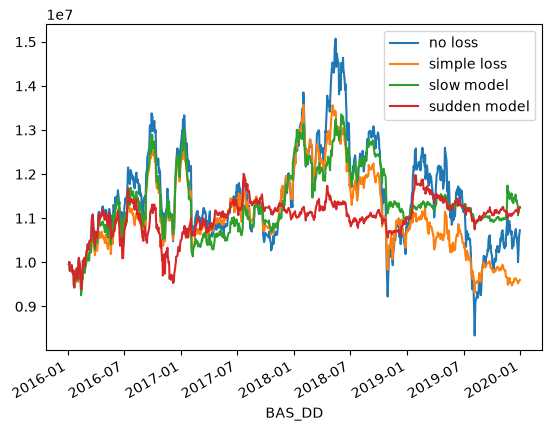

In [5]:
for name in ["no loss", "simple loss", "slow model", "sudden model"]:
    curves[name].plot(label=name)
plt.legend(); plt.show()

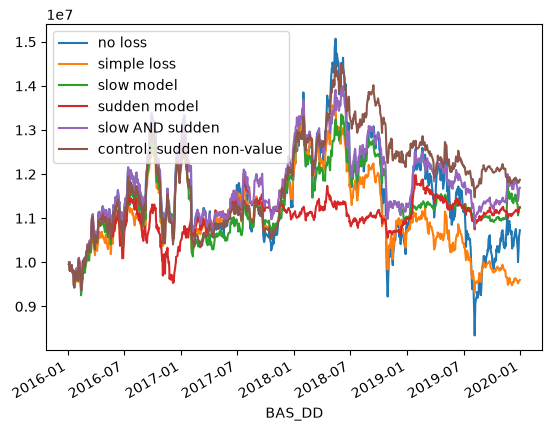

In [ ]:
# 비교용 선 추가
for name in curves:
    curves[name].plot(label=name)
plt.legend(); plt.show()

4. 무작위 기준선

이 기간에 19종목이 대체로 빠져서(보유 MDD 약 -45%) 아무 때나 팔아도 보유보다 나음.
그래서 "보유보다 좋다"는 모델 능력의 근거가 아님.
같은 매도 횟수로 무작위로 팔았을 때와 비교함.

- 종목무작위: 같은 매도일을 무작위 종목에 준다.
- 시점무작위: 같은 종목을 무작위 날짜에 판다.
- 백분위 = 무작위 결과 중 이 전략보다 나쁜 비율. **0.5 근처면 무작위와 구분되지 않는다.**

`draws=50`은 몇 분 걸린다. 결과표(README)는 200회 기준.

In [7]:
placebo = {name: jb.placebo(eng, basket, schedules[name], draws=50, seed=0)
           for name in ["slow model", "sudden model", "control: sudden non-value"]}
pd.DataFrame({name: {"종목무작위 백분위": p["random_stocks"]["percentile"],
                     "시점무작위 백분위": p["random_dates"]["percentile"],
                     "시점무작위 중앙 수익률": p["random_dates"]["median_cum_return"]}
              for name, p in placebo.items()}).T

,종목무작위 백분위,시점무작위 백분위,시점무작위 중앙 수익률
slow model,0.60,0.44,0.1425
sudden model,0.50,0.34,0.1902
control: sudden non-value,0.68,0.74,0.1313


. 결과 읽기 (2026-11-11, 200회 기준)

| 전략 | 누적수익률 | MDD | 시점무작위 백분위 |
|---|---|---|---|
| no loss | +7.6% | -44.7% | |
| slow model | +12.8% | -22.0% | 0.45 |
| sudden model | +12.9% | -18.4% | 0.28 |
| slow AND sudden | +17.3% | -22.8% | 0.49 |
| control: sudden non-value | +19.2% | -21.6% | 0.67 |

- 급락 모델은 보유보다 낫지만 **무작위로 판 것과 구분되지 않는다**. 서서히(임계) 모델도 같다.
- 급락 모델은 2017년 중반부터 많이 팔아 곡선이 평평하다. 2018년 초 상승은 놓쳤고, 2018년 하반기 하락과 2019년 8월 바닥은 피했다.
- 대조군 "비가치에 매도"가 가장 좋았다. 비가치 판정 뒤에도 주가가 계속 빠졌다는 뜻이라, 비가치를 "들고 있어도 된다"는 신호로 쓰면 안 된다.
- 한계: 19종목·한 번 매도라 검정력이 낮다(종목 한두 개로 몇 %p가 바뀐다). 엔진에 재매수가 없다. 급락 판정은 사람 검수 전이다.
- 자세한 내용: `models/sudden/README.md` "서서히 모델과 함께 백테스트", `docs/sudden_model.md`